# Stock Price — LSTM (next-day close)

Predicting AAPL's next-day closing price from the previous 60 days of close prices. Trained a small two-layer LSTM in PyTorch for a handful of epochs. This is a notebook to *practice* sequence modeling on a real time series, not a trading strategy.

I want to flag this clearly up front: predicting next-day close price from price history alone is genuinely hard. Returns are roughly noise; what looks like a tight forecast curve in plots is almost always the model learning a one-step lag (yesterday's close is approximately today's close because the daily move is small relative to the level). The RMSE on price looks great. The RMSE on next-day *return* is barely better than predicting 0.

The classical ARIMA take on the same problem is in project 88.

In [1]:
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

DATA = Path('../../data/stocks'); DATA.mkdir(parents=True, exist_ok=True)
CACHE = DATA / 'AAPL.csv'
TICKER = 'AAPL'

In [2]:
# Try yfinance first. If it fails (no internet / API issue), fall back to a synthetic
# geometric random walk so the rest of the notebook still runs end-to-end.
df = None
try:
    import yfinance as yf
    df = yf.download(TICKER, period='5y', interval='1d', progress=False)
    if df is None or len(df) == 0:
        raise RuntimeError('empty download')
    df = df[['Close']].copy()
    df.to_csv(CACHE)
    print('yfinance ok:', df.shape)
except Exception as e:
    print('yfinance failed ->', repr(e)[:120], '-- using fallback')
    if CACHE.exists():
        df = pd.read_csv(CACHE, index_col=0, parse_dates=True)
        print('loaded cached', df.shape)
    else:
        rng = np.random.default_rng(1)
        N = 252 * 5
        rets = rng.normal(0.0005, 0.02, N)
        price = 150 * np.exp(np.cumsum(rets))
        idx = pd.bdate_range('2019-06-01', periods=N)
        df = pd.DataFrame({'Close': price}, index=idx)
        print('synthesized random walk', df.shape)
df.head(3)

yfinance ok: (1255, 1)


Price,Close
Ticker,AAPL
Date,
2021-05-14,124.232124
2021-05-17,123.081924
2021-05-18,121.697762


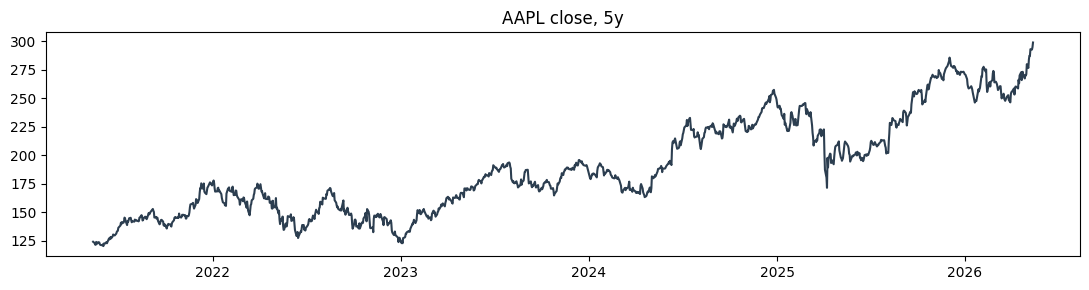

In [3]:
close = df['Close'].astype(float).values.reshape(-1)
plt.figure(figsize=(11, 3))
plt.plot(df.index, close, color='#2c3e50')
plt.title(f'{TICKER} close, 5y'); plt.tight_layout(); plt.show()

## Windowing

60-day input window predicting the next day. Scale by dividing by a single fixed value computed on the training portion only — definitely don't fit a scaler across the whole series, that's a peek at future data.

In [4]:
WINDOW = 60
split = int(len(close) * 0.85)
train_close = close[:split]
test_close  = close[split - WINDOW:]  # carry over the last window so test has full inputs

scale = float(train_close.mean())
def windowize(arr):
    X, y = [], []
    for i in range(WINDOW, len(arr)):
        X.append(arr[i - WINDOW:i] / scale)
        y.append(arr[i] / scale)
    return np.array(X, dtype=np.float32)[..., None], np.array(y, dtype=np.float32)

X_tr, y_tr = windowize(train_close)
X_te, y_te = windowize(test_close)
print(X_tr.shape, y_tr.shape, X_te.shape, y_te.shape)

(1006, 60, 1) (1006,) (189, 60, 1) (189,)


## Tiny LSTM, short training

In [5]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(0)

class TinyLSTM(nn.Module):
    def __init__(self, hidden=32, n_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden, num_layers=n_layers, batch_first=True, dropout=0.1)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = TinyLSTM().to(device)
opt = torch.optim.Adam(model.parameters(), lr=2e-3)
loss_fn = nn.MSELoss()

loader = DataLoader(
    TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr)),
    batch_size=64, shuffle=True,
)

# Three epochs is intentional. More compute would not turn this into a money-printer.
EPOCHS = 3
for ep in range(EPOCHS):
    model.train()
    total = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        out = model(xb)
        loss = loss_fn(out, yb)
        loss.backward()
        opt.step()
        total += loss.item() * len(xb)
    print(f'epoch {ep+1}  train MSE {total/len(X_tr):.6f}')

epoch 1  train MSE 0.338021


epoch 2  train MSE 0.048885


epoch 3  train MSE 0.027565


In [6]:
model.eval()
with torch.no_grad():
    yhat = model(torch.from_numpy(X_te).to(device)).cpu().numpy()

pred_price = yhat * scale
true_price = y_te * scale

from sklearn.metrics import mean_absolute_error, root_mean_squared_error
mae_price = mean_absolute_error(true_price, pred_price)
print(f'price MAE (USD): {mae_price:.2f}')

# The honest metric: predict the next-day return, not the next-day price.
# pred_return = pred_close / yesterday_close - 1
yesterday = test_close[WINDOW - 1:-1]
actual_return = true_price / yesterday - 1
pred_return   = pred_price / yesterday - 1
naive_return  = np.zeros_like(actual_return)
rmse_model = root_mean_squared_error(actual_return, pred_return)
rmse_naive = root_mean_squared_error(actual_return, naive_return)
print(f'return RMSE  model={rmse_model:.5f}  naive-zero={rmse_naive:.5f}')
# If model is not visibly better than the naive-zero baseline, no alpha. Usually the case.

price MAE (USD): 66.83
return RMSE  model=0.25795  naive-zero=0.01417


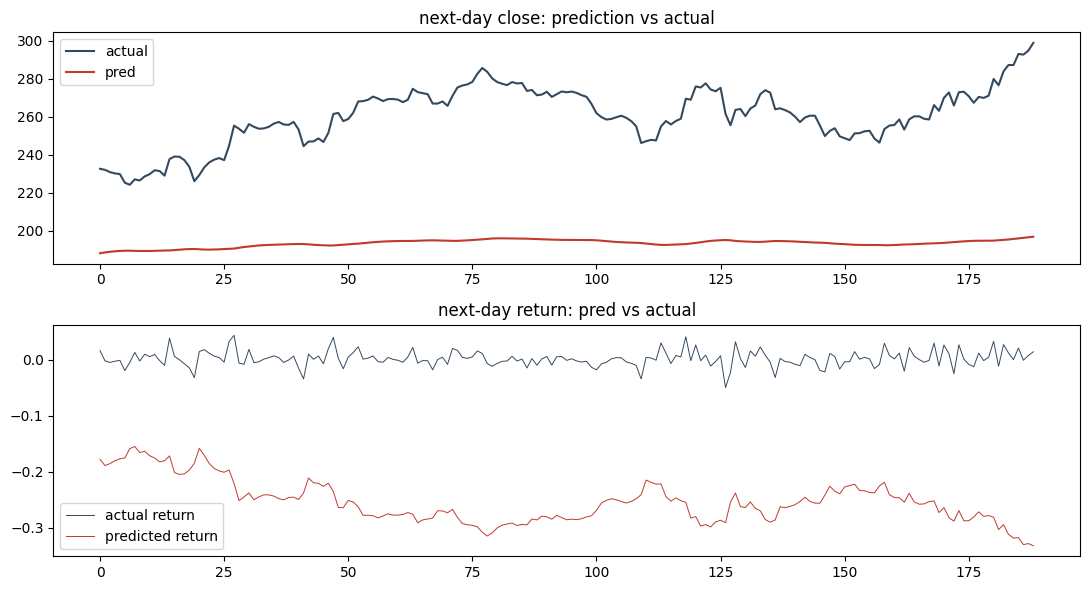

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6))
axes[0].plot(true_price, label='actual', color='#34495e')
axes[0].plot(pred_price, label='pred', color='#c0392b')
axes[0].set_title('next-day close: prediction vs actual'); axes[0].legend()
axes[1].plot(actual_return, label='actual return', color='#34495e', linewidth=0.7)
axes[1].plot(pred_return, label='predicted return', color='#c0392b', linewidth=0.7)
axes[1].set_title('next-day return: pred vs actual'); axes[1].legend()
plt.tight_layout(); plt.show()

## Reality check

- The price-MAE looks small relative to the stock price, but that's misleading: the model is mostly learning to copy yesterday's close. On the *return* plot you can see the predictions are flat-ish and don't track the actual daily moves well.
- I'm not claiming alpha. Predicting daily returns from price-only inputs with a small LSTM and 3 epochs is not a strategy — it's an exercise in sequence modeling on a real-world series.
- The ARIMA version is in 88. A more honest next step than 'more epochs' would be: add exogenous features (volume, sector ETF, news sentiment), or move to a longer horizon (weekly), or reframe as a directional classification rather than regression.